# BÀI 3: Sử dụng Neural Network phân lớp bộ dữ liệu MNIST bằng Keras kết hợp K-Fold Cross Validation (K = 10)


## Chuẩn bị thư viện

In [1]:
print("NguyenDucTinh - 6451071077")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import KFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)

NguyenDucTinh - 6451071077
TensorFlow version: 2.21.0


## Câu a: Đọc bộ dữ liệu MNIST từ Keras

In [2]:
print("NguyenDucTinh - 6451071077")

# Đọc dữ liệu MNIST từ thư viện Keras
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()

print("Đã tải dữ liệu MNIST thành công!")

NguyenDucTinh - 6451071077
Đã tải dữ liệu MNIST thành công!


## Câu b: In kích thước tập train và test

In [3]:
print("NguyenDucTinh - 6451071077")

print("Kích thước tập train:")
print("train_images:", train_images.shape)
print("train_labels:", train_labels.shape)

print("\nKích thước tập test:")
print("test_images:", test_images.shape)
print("test_labels:", test_labels.shape)

NguyenDucTinh - 6451071077
Kích thước tập train:
train_images: (60000, 28, 28)
train_labels: (60000,)

Kích thước tập test:
test_images: (10000, 28, 28)
test_labels: (10000,)


## Câu c: Chuẩn hóa giá trị pixel về đoạn [0, 1]

In [4]:
print("NguyenDucTinh - 6451071077")

# Chuyển kiểu dữ liệu sang float32
train_images = train_images.astype('float32')
test_images = test_images.astype('float32')

# Chuẩn hóa pixel từ [0,255] về [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

print("Giá trị pixel nhỏ nhất:", train_images.min())
print("Giá trị pixel lớn nhất:", train_images.max())

print("Đã chuẩn hóa dữ liệu thành công!")

NguyenDucTinh - 6451071077


Giá trị pixel nhỏ nhất: 0.0
Giá trị pixel lớn nhất: 1.0
Đã chuẩn hóa dữ liệu thành công!


## Câu d: Xây dựng mô hình Neural Network

In [5]:
print("NguyenDucTinh - 6451071077")

def create_model():

    # Khởi tạo mô hình Sequential
    model = keras.Sequential([

        # Chuyển ảnh 28x28 thành vector 784 phần tử
        layers.Flatten(input_shape=(28, 28)),

        # Lớp ẩn gồm 128 neuron, hàm kích hoạt ReLU
        layers.Dense(128, activation='relu'),

        # Lớp đầu ra gồm 10 neuron tương ứng 10 chữ số
        layers.Dense(10, activation='softmax')
    ])

    # Biên dịch mô hình
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# Kiểm tra cấu trúc mô hình
model = create_model()
model.summary()

NguyenDucTinh - 6451071077


c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Câu e: Huấn luyện K-Fold Cross Validation

In [6]:
print("NguyenDucTinh - 6451071077")

# Khởi tạo KFold với 10 Fold
kfold = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Mảng lưu các mô hình sau khi huấn luyện
models = []

# Mảng lưu Accuracy và Loss của từng Fold
accuracy_per_fold = []
loss_per_fold = []

print("Đã khởi tạo K-Fold Cross Validation với K = 10")

fold_no = 1

for train_index, val_index in kfold.split(train_images):

    print("\n====================================")
    print("ĐANG HUẤN LUYỆN FOLD:", fold_no)
    print("====================================")

    # Chia dữ liệu thành tập train và validation
    X_train_fold = train_images[train_index]
    X_val_fold = train_images[val_index]

    y_train_fold = train_labels[train_index]
    y_val_fold = train_labels[val_index]

    print("Kích thước X_train_fold:", X_train_fold.shape)
    print("Kích thước X_val_fold:", X_val_fold.shape)

    # Tạo mô hình mới cho từng Fold
    model = create_model()

    # Huấn luyện mô hình
    history = model.fit(
        X_train_fold,
        y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=5,
        batch_size=32,
        verbose=1
    )

    # Đánh giá mô hình trên tập validation
    loss, accuracy = model.evaluate(
        X_val_fold,
        y_val_fold,
        verbose=0
    )

    # Lưu mô hình vào mảng models
    models.append(model)

    # Lưu Accuracy và Loss
    accuracy_per_fold.append(accuracy)
    loss_per_fold.append(loss)

    # Lưu mô hình của từng Fold thành file riêng
    model.save(f'mnist_model_fold_{fold_no}.keras')

    # In kết quả của Fold
    print("\nKẾT QUẢ FOLD", fold_no)
    print("Loss:", loss)
    print("Accuracy:", accuracy * 100, "%")

    fold_no += 1

print("\nĐÃ HOÀN THÀNH HUẤN LUYỆN 10 FOLD!")

NguyenDucTinh - 6451071077
Đã khởi tạo K-Fold Cross Validation với K = 10

ĐANG HUẤN LUYỆN FOLD: 1
Kích thước X_train_fold: (54000, 28, 28)
Kích thước X_val_fold: (6000, 28, 28)
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9218 - loss: 0.2774 - val_accuracy: 0.9545 - val_loss: 0.1557
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9636 - loss: 0.1237 - val_accuracy: 0.9700 - val_loss: 0.1086
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9747 - loss: 0.0842 - val_accuracy: 0.9738 - val_loss: 0.0907
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9811 - loss: 0.0632 - val_accuracy: 0.9758 - val_loss: 0.0780
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9853 - loss: 0.0481 - val_accuracy: 0.9732 - val_loss: 0.0845

KẾT QUẢ FOLD 1
Loss: 0.08454926311969757
Accuracy: 97.31666445732117 %

ĐANG HUẤN LUYỆN FOLD: 2
Kích thước X_train_fold: (54000, 28, 28)
Kích thước X_val_fold: (6000, 28, 28)

## Câu f: Tính Mean và Standard Deviation

In [7]:
print("NguyenDucTinh - 6451071077")

# Tính Mean Accuracy
mean_accuracy = np.mean(accuracy_per_fold)

# Tính độ lệch chuẩn Accuracy
std_accuracy = np.std(accuracy_per_fold)

# Tính Mean Loss
mean_loss = np.mean(loss_per_fold)

# Tính độ lệch chuẩn Loss
std_loss = np.std(loss_per_fold)

print("========== KẾT QUẢ TRUNG BÌNH 10 FOLD ==========")

print("Mean Accuracy:", mean_accuracy)
print("Mean Accuracy (%):", mean_accuracy * 100)

print("Standard Deviation Accuracy:", std_accuracy)
print("Standard Deviation Accuracy (%):", std_accuracy * 100)

print("Mean Loss:", mean_loss)
print("Standard Deviation Loss:", std_loss)

NguyenDucTinh - 6451071077
========== KẾT QUẢ TRUNG BÌNH 10 FOLD ==========
Mean Accuracy: 0.9730166733264923
Mean Accuracy (%): 97.30166733264923
Standard Deviation Accuracy: 0.001146132094707184
Standard Deviation Accuracy (%): 0.11461320947071839
Mean Loss: 0.08876807987689972
Standard Deviation Loss: 0.0029299606904916744


## Câu g: Vẽ biểu đồ Accuracy và Loss

NguyenDucTinh - 6451071077


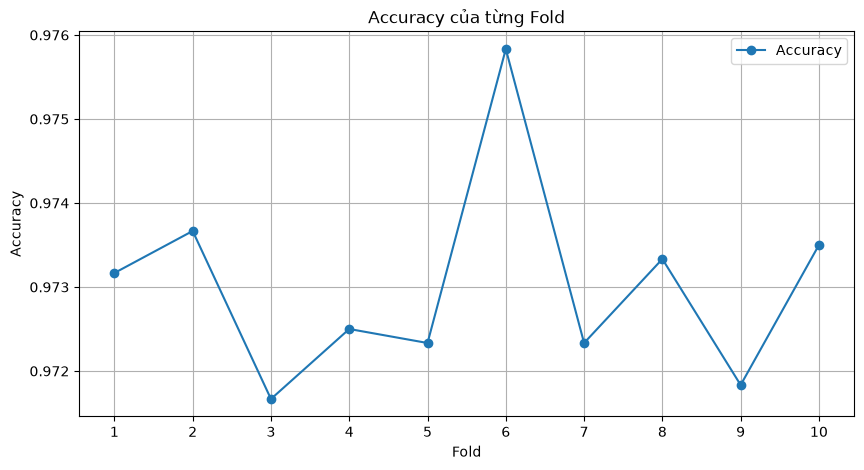

In [8]:
print("NguyenDucTinh - 6451071077")

#biểu đồ Accuracy sau mỗi Fold

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 11),
    accuracy_per_fold,
    marker='o',
    label='Accuracy'
)

plt.title('Accuracy của từng Fold')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.xticks(range(1, 11))
plt.grid(True)
plt.legend()

plt.show()

NguyenDucTinh - 6451071077


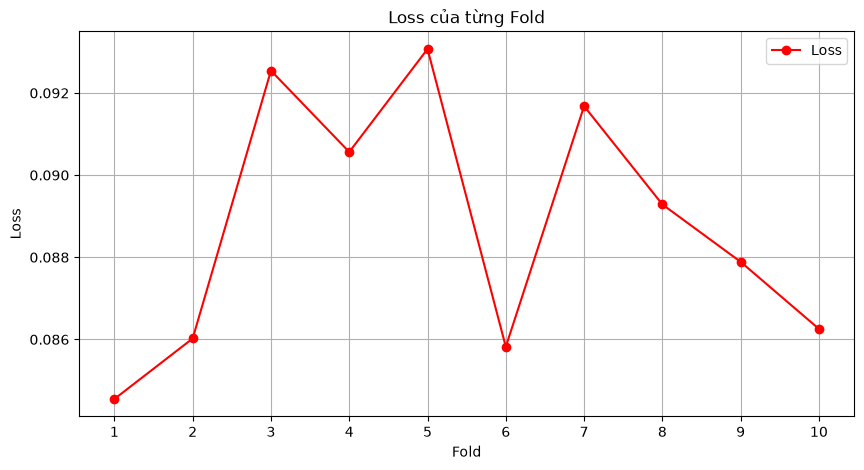

In [9]:
print("NguyenDucTinh - 6451071077")

#biểu đồ Loss sau mỗi Fold

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 11),
    loss_per_fold,
    marker='o',
    color='red',
    label='Loss'
)

plt.title('Loss của từng Fold')
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.xticks(range(1, 11))
plt.grid(True)
plt.legend()

plt.show()

## Câu h: Chọn mô hình có Accuracy tốt nhất

In [10]:
print("NguyenDucTinh - 6451071077")

# Tìm vị trí Fold có Accuracy cao nhất
best_index = np.argmax(accuracy_per_fold)

# Lấy mô hình có Accuracy tốt nhất
best_model = models[best_index]

print("Fold có Accuracy tốt nhất:", best_index + 1)

print("Accuracy tốt nhất:",
      accuracy_per_fold[best_index] * 100, "%")

print("Đã chọn mô hình tốt nhất thành công!")

NguyenDucTinh - 6451071077
Fold có Accuracy tốt nhất: 6
Accuracy tốt nhất: 97.58333563804626 %
Đã chọn mô hình tốt nhất thành công!


## Câu i: Đánh giá mô hình trên tập test

In [11]:
print("NguyenDucTinh - 6451071077")

# Đánh giá mô hình tốt nhất trên tập test
test_loss, test_accuracy = best_model.evaluate(
    test_images,
    test_labels,
    verbose=0
)

print("========== KẾT QUẢ TRÊN TẬP TEST ==========")

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

NguyenDucTinh - 6451071077
========== KẾT QUẢ TRÊN TẬP TEST ==========
Test Loss: 0.08443249762058258
Test Accuracy: 97.4399983882904 %


## Câu j: Tính Precision, Recall, F1-score

In [12]:
print("NguyenDucTinh - 6451071077")

# Dự đoán xác suất của 10 lớp
y_pred_prob = best_model.predict(test_images)

# Lấy lớp có xác suất cao nhất
y_pred = np.argmax(y_pred_prob, axis=1)

# In Precision, Recall, F1-score
print("========== CLASSIFICATION REPORT ==========")

print(classification_report(
    test_labels,
    y_pred,
    digits=4
))

NguyenDucTinh - 6451071077
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step
========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0     0.9748    0.9888    0.9818       980
           1     0.9869    0.9921    0.9895      1135
           2     0.9665    0.9787    0.9726      1032
           3     0.9387    0.9851    0.9614      1010
           4     0.9776    0.9796    0.9786       982
           5     0.9919    0.9574    0.9743       892
           6     0.9761    0.9812    0.9787       958
           7     0.9654    0.9757    0.9705      1028
           8     0.9839    0.9394    0.9611       974
           9     0.9868    0.9613    0.9739      1009

    accuracy                         0.9744     10000
   macro avg     0.9749    0.9739    0.9742     10000
weighted avg     0.9747    0.9744    0.9744     10000



## Câu k: Hiển thị Confusion Matrix bằng Heatmap

NguyenDucTinh - 6451071077


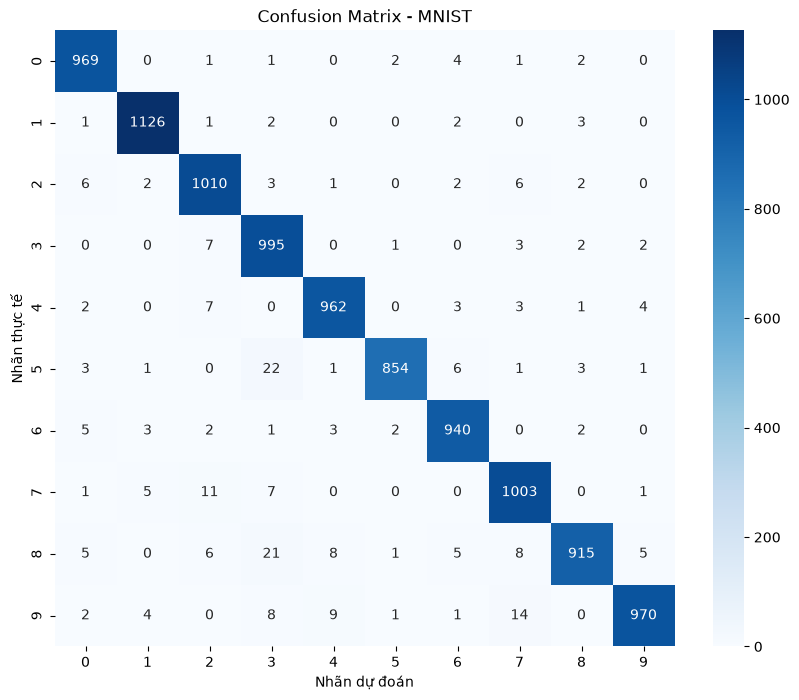

In [13]:
print("NguyenDucTinh - 6451071077")

# Tính Confusion Matrix
cm = confusion_matrix(test_labels, y_pred)

# Vẽ Heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title('Confusion Matrix - MNIST')
plt.xlabel('Nhãn dự đoán')
plt.ylabel('Nhãn thực tế')

plt.show()

## Câu l: Hiển thị kết quả phân lớp 5 ảnh đầu tiên

NguyenDucTinh - 6451071077
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


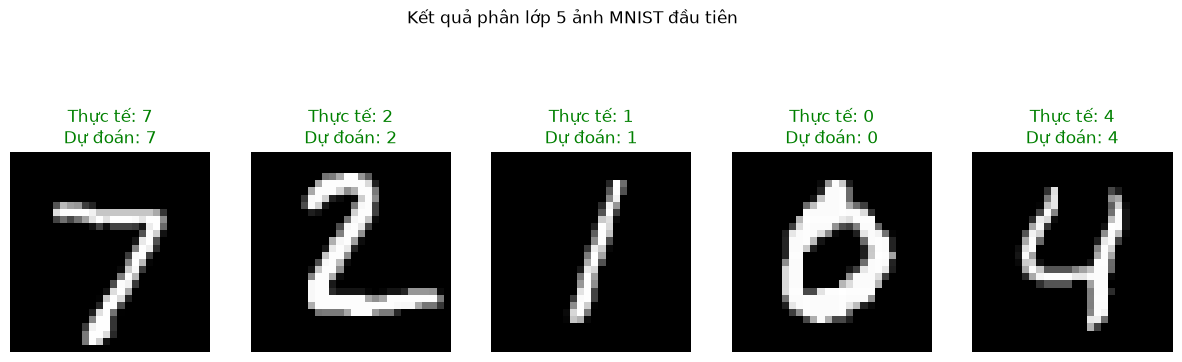

========== KẾT QUẢ DỰ ĐOÁN ==========
Ảnh 1: Nhãn thực tế = 7, Nhãn dự đoán = 7
Ảnh 2: Nhãn thực tế = 2, Nhãn dự đoán = 2
Ảnh 3: Nhãn thực tế = 1, Nhãn dự đoán = 1
Ảnh 4: Nhãn thực tế = 0, Nhãn dự đoán = 0
Ảnh 5: Nhãn thực tế = 4, Nhãn dự đoán = 4


In [14]:
print("NguyenDucTinh - 6451071077")

# Dự đoán 5 ảnh đầu tiên trong tập test
predictions = best_model.predict(test_images[:5])

# Lấy nhãn dự đoán
predicted_labels = np.argmax(predictions, axis=1)

# Hiển thị 5 ảnh
plt.figure(figsize=(15, 5))

for i in range(5):

    plt.subplot(1, 5, i + 1)

    # Hiển thị ảnh
    plt.imshow(test_images[i], cmap='gray')

    # Lấy nhãn thực tế và nhãn dự đoán
    actual = test_labels[i]
    predicted = predicted_labels[i]

    plt.title(
        f'Thực tế: {actual}\nDự đoán: {predicted}',
        color='green' if actual == predicted else 'red'
    )

    plt.axis('off')

plt.suptitle('Kết quả phân lớp 5 ảnh MNIST đầu tiên')

plt.show()

# In kết quả dạng văn bản
print("========== KẾT QUẢ DỰ ĐOÁN ==========")

for i in range(5):
    print(
        f"Ảnh {i + 1}: "
        f"Nhãn thực tế = {test_labels[i]}, "
        f"Nhãn dự đoán = {predicted_labels[i]}"
    )